# Chinese (Mandarin) replication of the male abstraction bias (Fig. 1a)

Same procedure as the Dutch, Estonian and Persian replications (Supplementary Sections on the cross-language tests): a gender axis is built from seed pairs in Chinese-trained word vectors (Eq. S1 of the supplement: the mean over seed pairs of unit(male) − unit(female), re-normalised), every rated two-character word is scored by its cosine with the axis (positive = masculine), and the score is correlated with human concreteness ratings. A negative correlation means that more masculine words are more abstract.

**Norms.**
* `zh-chan-tse-2024.csv` — Chan & Tse (2024, *Behav. Res. Methods* 56, 7574–7601): 25,281 two-character words of standard written Chinese rated for concreteness (1–7), familiarity, imageability, valence and arousal by Cantonese-speaking participants in Hong Kong; the file gives each word in traditional and simplified characters, and the simplified forms are used here (25,044 distinct forms). This is the main analysis (`results_zh/`).
* `zh-song-li-2021.csv` — Song & Li (2021, *SAGE Open* 11): 3,783 simplified two-character words rated on the same 1–7 scale by Mainland Mandarin speakers; run as a check that the result does not depend on the Hong Kong sample (`results_zh_song/`).

Both files are unmodified copies of `Chan2024.csv` and `Song2021.csv` from the ManyNorms / semanticprimeR GitHub release (SemanticPriming/semanticprimeR, tag v0.0.1), which redistributes the published norms.

**Word vectors.** The static vector table of spaCy's `zh_core_web_lg` pipeline, version 3.8.0 (500,000 entries × 300 dimensions; fastText CBOW vectors trained by Explosion on the Chinese portions of OSCAR Common Crawl and Wikipedia). Install with

```
pip install spacy
pip install https://github.com/explosion/spacy-models/releases/download/zh_core_web_lg-3.8.0/zh_core_web_lg-3.8.0-py3-none-any.whl
```

**Seed pairs.** Primary (the counterparts of the Dutch and Estonian primary sets): 男人/女人 (man/woman), 男孩/女孩 (boy/girl), 男性/女性 (male/female), 父亲/母亲 (father/mother), 哥哥/姐姐 (elder brother/elder sister). Extended: the primary pairs plus 儿子/女儿, 叔叔/阿姨, 国王/女王, 先生/女士, 爷爷/奶奶. Pronoun variant: 他/她 in place of 哥哥/姐姐 (the written pronoun distinction is unambiguous in Chinese, unlike Dutch *zij*/*haar*).

**Outputs** (identical in content to the files committed alongside this notebook): `stats_*.csv` (every specification), `deciles_*.csv` (mean concreteness by gender-score decile), `pole_sensitivity_*.csv` (seed-pair sensitivity with the extreme words), `scores_*.csv` (per-word gender scores), `seeds_*.json`, and `figS_chinese_replication.{png,pdf}` (Supplementary Fig.).

**Requirements:** Python 3, `numpy pandas scipy statsmodels matplotlib spacy` and the model above (`pip install -r requirements.txt`). Length is not controlled because every item is a two-character word; word frequency is the log corpus frequency distributed with each set of norms.

In [1]:
# ---------------------------------------------------------------- configuration
from pathlib import Path
import re

BASE = Path.cwd()                                   # the folder holding this notebook and the two norm files
NORMS_CHAN = BASE / "zh-chan-tse-2024.csv"          # Chan & Tse (2024) — main analysis
NORMS_SONG = BASE / "zh-song-li-2021.csv"           # Song & Li (2021)  — Mainland Mandarin check
OUT_CHAN, OUT_SONG = BASE / "results_zh", BASE / "results_zh_song"
for p in (NORMS_CHAN, NORMS_SONG): assert p.exists(), f"missing file: {p}"
OUT_CHAN.mkdir(exist_ok=True); OUT_SONG.mkdir(exist_ok=True)

LANGNAME, SCALE, SPACY_MODEL = "Chinese", "1–7", "zh_core_web_lg"
SEEDS = {
    "primary":  [("男人", "女人"), ("男孩", "女孩"), ("男性", "女性"), ("父亲", "母亲"), ("哥哥", "姐姐")],
    "extended": [("男人", "女人"), ("男孩", "女孩"), ("男性", "女性"), ("父亲", "母亲"), ("哥哥", "姐姐"),
                 ("儿子", "女儿"), ("叔叔", "阿姨"), ("国王", "女王"), ("先生", "女士"), ("爷爷", "奶奶")],
    "pronoun":  [("男人", "女人"), ("他", "她"), ("男性", "女性"), ("男孩", "女孩"), ("父亲", "母亲")],
}
# gendered word pairs never used as seeds: a valid axis orders the male above the female member
VALIDATION = [("丈夫", "妻子"), ("弟弟", "妹妹"), ("爸爸", "妈妈"), ("新郎", "新娘"), ("王子", "公主"),
              ("少年", "少女"), ("男子", "女子"), ("公公", "婆婆"), ("外公", "外婆"), ("孙子", "孙女"),
              ("侄子", "侄女"), ("男生", "女生"), ("绅士", "淑女"), ("男友", "女友"), ("和尚", "尼姑"),
              ("皇帝", "皇后"), ("帅哥", "美女"), ("男神", "女神")]
# words containing a gender-marking character count as 'lexically gendered' for the exclusion check
GENDERED_RE = re.compile(r"[男女父母爸妈哥姐弟妹夫妻公婆郎娘姑叔舅姨翁妇嫂爷奶兄嬷媳婿姥婶他她]")
print("norms:", NORMS_CHAN.name, "+", NORMS_SONG.name, "| outputs:", OUT_CHAN.name, "+", OUT_SONG.name)

norms: zh-chan-tse-2024.csv + zh-song-li-2021.csv | outputs: results_zh + results_zh_song


In [2]:
# ---------------------------------------------------------------- imports and helpers
import json
import numpy as np, pandas as pd
from scipy import stats
import statsmodels.api as sm
import matplotlib.pyplot as plt
pd.set_option("display.width", 220); pd.set_option("display.max_rows", 200); pd.set_option("display.max_colwidth", 80)

def unit(v):
    n = np.linalg.norm(v); return v / n if n > 0 else v

_warned = set()
def gender_axis(lookup, pairs):
    # Eq. S1: mean over seed pairs of unit(male) - unit(female), re-normalised
    diffs, used = [], []
    for m, f in pairs:
        vm, vf = lookup(m), lookup(f)
        if vm is None or vf is None:
            if (m, f) not in _warned: print(f"   seed pair missing in the vectors: ({m}, {f})"); _warned.add((m, f))
            continue
        diffs.append(unit(vm) - unit(vf)); used.append((m, f))
    if not diffs: raise RuntimeError("no seed pairs available in the vectors")
    return unit(np.mean(diffs, axis=0)), used

def score_terms(lookup, axis, words):
    g = np.full(len(words), np.nan)
    for i, w in enumerate(words):
        v = lookup(w)
        if v is not None: g[i] = float(unit(v) @ axis)
    return g

def fisher_ci(r, n):
    if n < 4 or abs(r) >= 1: return (np.nan, np.nan)
    z, se = np.arctanh(r), 1 / np.sqrt(n - 3); q = stats.norm.ppf(0.975)
    return tuple(np.tanh([z - q * se, z + q * se]))

def zs(x):
    x = np.asarray(x, float); return (x - np.nanmean(x)) / np.nanstd(x)

def describe(df, label):
    d = df.dropna(subset=["gender", "conc"])
    r, p = stats.pearsonr(d.gender, d.conc); lo, hi = fisher_ci(r, len(d)); rho, _ = stats.spearmanr(d.gender, d.conc)
    return dict(specification=label, r=r, ci_lo=lo, ci_hi=hi, p=p, rho=rho, n=len(d))

def ols_beta(df, controls, label):
    # standardised coefficient on concreteness (HC1 SEs) in a regression of z(gender) on z(concreteness) + controls
    cols = ["conc"] + controls
    d = df.dropna(subset=["gender"] + cols)
    X = sm.add_constant(np.column_stack([zs(d[c]) for c in cols]))
    res = sm.OLS(zs(d.gender), X).fit(cov_type="HC1"); ci = res.conf_int()[1]
    return dict(specification=label, r=res.params[1], ci_lo=ci[0], ci_hi=ci[1], p=res.pvalues[1], rho=np.nan, n=len(d))

def deciles(df):
    d = df.dropna(subset=["gender", "conc"]).copy()
    d["decile"] = pd.qcut(d.gender.rank(method="first"), 10, labels=range(1, 11)).astype(int)
    return d.groupby("decile").conc.agg(["mean", "count"]).reset_index()

def validation_accuracy(lookup, axis, used):
    hits = []
    for m, f in VALIDATION:
        if (m, f) in used: continue
        vm, vf = lookup(m), lookup(f)
        if vm is None or vf is None: continue
        hits.append(float(unit(vm) @ axis) > float(unit(vf) @ axis))
    return (np.mean(hits) if hits else np.nan), len(hits)

def load_norms(path, word_col, conc_col, sd_col=None, freq_col=None, log_freq=False):
    raw = pd.read_csv(path, keep_default_na=False, na_values=[""])
    norms = pd.DataFrame({"word": raw[word_col].astype(str).str.strip(),
                          "conc": pd.to_numeric(raw[conc_col], errors="coerce"),
                          "conc_sd": pd.to_numeric(raw[sd_col], errors="coerce") if sd_col else np.nan,
                          "norm_freq": pd.to_numeric(raw[freq_col], errors="coerce") if freq_col else np.nan})
    if log_freq: norms["norm_freq"] = np.log1p(norms["norm_freq"])
    norms = norms[(norms.word != "") & norms.conc.notna()]
    norms = norms.groupby("word", as_index=False).agg(conc=("conc", "mean"), conc_sd=("conc_sd", "mean"), norm_freq=("norm_freq", "mean"))
    norms["length"] = norms.word.str.len()
    norms["logfreq"] = norms["norm_freq"]          # log corpus frequency distributed with the norms
    return norms

## 1. Chinese word vectors (spaCy `zh_core_web_lg`)

In [3]:
import spacy
nlp = spacy.load(SPACY_MODEL, exclude=["tagger", "parser", "ner", "lemmatizer", "attribute_ruler", "morphologizer", "senter"])
print(SPACY_MODEL, "v" + nlp.meta["version"], "| vectors", nlp.vocab.vectors.shape, "| sources:", [s.get("name") for s in nlp.meta.get("sources", [])])

def lookup(w):
    for cand in (w, w.lower()):
        lex = nlp.vocab[cand]
        if lex.has_vector and lex.vector_norm > 0: return np.asarray(lex.vector, dtype=np.float32)
    return None

missing = sorted({p for s in SEEDS.values() for p in s if lookup(p[0]) is None or lookup(p[1]) is None})
print("seed pairs missing from the vectors:", missing or "none")

zh_core_web_lg v3.8.0 | vectors (500000, 300) | sources: ['OntoNotes 5', 'CoreNLP Universal Dependencies Converter', 'Explosion fastText Vectors (cbow, OSCAR Common Crawl + Wikipedia)']
seed pairs missing from the vectors: none


## 2. The analysis

One function runs the full set of statistics for a norm set: for each seed set, the gender scores, the held-out pair check, the correlation with concreteness under every specification reported in the Supplementary Table (no controls; excluding lexically gendered words and seeds; excluding the 5 % and 10 % most gendered words; reliably rated words; HC1 regressions with and without log frequency), the decile means, and the seed-pair sensitivity (leave-one-pair-out, single pairs, pronoun variant, first principal component of the extended set) with the most feminine and most masculine words under each axis. Length is constant (two characters) and is not controlled.

In [4]:
def run_all(norms, tag, out):
    rows, dec, seeds_used, scores = [], [], {}, norms[["word", "conc"]].copy()
    for pset, pairs in SEEDS.items():
        axis, used = gender_axis(lookup, pairs); seeds_used[pset] = used
        g = score_terms(lookup, axis, norms.word.tolist())
        df = norms.copy(); df["gender"] = g; scores[f"gender::{pset}"] = g
        acc, nval = validation_accuracy(lookup, axis, used)
        print(f"  seeds={pset}: {len(used)}/{len(pairs)} pairs; {int(np.isfinite(g).sum()):,}/{len(df):,} words scored; "
              f"held-out gendered pairs ordered correctly: {acc:.2f} (n={nval})")
        R = [describe(df, "all terms (no controls)")]
        seedset = {w for p in used for w in p}
        R.append(describe(df[~(df.word.str.contains(GENDERED_RE) | df.word.isin(seedset))], "excl. lexically gendered terms + seeds"))
        for q in (0.05, 0.10):
            thr = df.gender.abs().quantile(1 - q); R.append(describe(df[df.gender.abs() < thr], f"excl. {int(q*100)}% most gendered terms"))
        if df.conc_sd.notna().sum() > 100:
            R.append(describe(df[df.conc_sd <= df.conc_sd.median()], "rater s.d. of concreteness <= median (reliably rated)"))
        if df.logfreq.notna().sum() > 100:
            R.append(ols_beta(df, ["logfreq"], "OLS: + log frequency"))
        R.append(ols_beta(df, [], "OLS: no controls"))
        for r_ in R: r_.update(seeds=pset, validation_accuracy=acc, validation_pairs=nval)
        rows += R
        dd = deciles(df); dd["seeds"] = pset; dec.append(dd)
    # seed-pair sensitivity
    prim, ext = SEEDS["primary"], SEEDS["extended"]
    specs = {"primary set (5 pairs)": prim, "extended set (10 pairs)": ext}
    for p in prim: specs[f"primary minus {p[0]}/{p[1]}"] = [q for q in prim if q != p]
    for p in ext: specs[f"single pair {p[0]}/{p[1]}"] = [p]
    for k, v in SEEDS.items():
        if k not in ("primary", "extended"):
            specs[f"{k} set"] = v
            for p in v:
                if p not in ext: specs[f"single pair {p[0]}/{p[1]}"] = [p]
    PS = []
    for label, pairs in specs.items():
        try: axis, used = gender_axis(lookup, pairs)
        except RuntimeError: continue
        g = score_terms(lookup, axis, norms.word.tolist()); ok = np.isfinite(g)
        r, p = stats.pearsonr(g[ok], norms.conc.values[ok]); lo, hi = fisher_ci(r, ok.sum())
        d = pd.DataFrame({"w": norms.word, "g": g}).dropna().sort_values("g")
        PS.append(dict(specification=label, n_pairs=len(used), r=r, ci_lo=lo, ci_hi=hi, p=p, n=int(ok.sum()),
                       most_female=", ".join(d.w.head(8)), most_male=", ".join(d.w.tail(8)[::-1])))
    D = np.vstack([unit(unit(lookup(m)) - unit(lookup(f))) for m, f in ext if lookup(m) is not None and lookup(f) is not None])
    U, s, Vt = np.linalg.svd(D, full_matrices=False); pc1 = Vt[0]; pc1 = pc1 if D.mean(0) @ pc1 > 0 else -pc1
    g = score_terms(lookup, unit(pc1), norms.word.tolist()); ok = np.isfinite(g)
    r, p = stats.pearsonr(g[ok], norms.conc.values[ok]); lo, hi = fisher_ci(r, ok.sum())
    d = pd.DataFrame({"w": norms.word, "g": g}).dropna().sort_values("g")
    PS.append(dict(specification=f"PC1 of extended set (var. expl. {s[0]**2/(s**2).sum():.2f}; loadings {np.round(D@pc1,2).tolist()})",
                   n_pairs=len(D), r=r, ci_lo=lo, ci_hi=hi, p=p, n=int(ok.sum()),
                   most_female=", ".join(d.w.head(8)), most_male=", ".join(d.w.tail(8)[::-1])))
    # write
    S = pd.DataFrame(rows)[["seeds", "specification", "r", "ci_lo", "ci_hi", "p", "rho", "n", "validation_accuracy", "validation_pairs"]]
    S.insert(0, "model", SPACY_MODEL); S.insert(0, "language", LANGNAME)
    DEC = pd.concat(dec); PS = pd.DataFrame(PS)
    S.to_csv(out / f"stats_{tag}.csv", index=False); DEC.to_csv(out / f"deciles_{tag}.csv", index=False)
    PS.to_csv(out / f"pole_sensitivity_{tag}.csv", index=False); scores.to_csv(out / f"scores_{tag}.csv", index=False)
    json.dump(seeds_used, open(out / f"seeds_{tag}.json", "w", encoding="utf8"), ensure_ascii=False, indent=1)
    return S, DEC, PS

## 3. Main analysis: Chan & Tse (2024) norms

In [5]:
norms = load_norms(NORMS_CHAN, word_col="word_chinese_simplified", conc_col="concrete_mean", sd_col="concrete_sd", freq_col="frequency_log_word")
print(f"{len(norms):,} distinct rated words; concreteness mean {norms.conc.mean():.2f} (sd {norms.conc.std():.2f}) on a {SCALE} scale")
S, DEC, PS = run_all(norms, "zh", OUT_CHAN)
S.drop(columns=["language", "model"]).round(4)

25,044 distinct rated words; concreteness mean 4.60 (sd 0.72) on a 1–7 scale


  seeds=primary: 5/5 pairs; 23,961/25,044 words scored; held-out gendered pairs ordered correctly: 1.00 (n=18)


  seeds=extended: 10/10 pairs; 23,961/25,044 words scored; held-out gendered pairs ordered correctly: 0.94 (n=18)


  seeds=pronoun: 5/5 pairs; 23,961/25,044 words scored; held-out gendered pairs ordered correctly: 0.94 (n=18)


,seeds,specification,r,ci_lo,ci_hi,p,rho,n,validation_accuracy,validation_pairs
0,primary,all terms (no controls),-0.1106,-0.1231,-0.0981,0.0,-0.1008,23961,1.0000,18
1,primary,excl. lexically gendered terms + seeds,-0.0954,-0.1081,-0.0827,0.0,-0.0931,23559,1.0000,18
2,primary,excl. 5% most gendered terms,-0.0885,-0.1013,-0.0755,0.0,-0.0860,22762,1.0000,18
3,primary,excl. 10% most gendered terms,-0.0819,-0.0951,-0.0686,0.0,-0.0803,21564,1.0000,18
4,primary,rater s.d. of concreteness <= median (reliably rated),-0.1290,-0.1465,-0.1115,0.0,-0.1250,12152,1.0000,18
5,primary,OLS: + log frequency,-0.1116,-0.1259,-0.0972,0.0,NaN,19832,1.0000,18
6,primary,OLS: no controls,-0.1106,-0.1236,-0.0976,0.0,NaN,23961,1.0000,18
7,extended,all terms (no controls),-0.1929,-0.2051,-0.1807,0.0,-0.1933,23961,0.9444,18
8,extended,excl. lexically gendered terms + seeds,-0.1875,-0.1998,-0.1751,0.0,-0.1895,23556,0.9444,18
9,extended,excl. 5% most gendered terms,-0.1841,-0.1966,-0.1715,0.0,-0.1819,22762,0.9444,18


In [6]:
print("Mean concreteness by gender-score decile (1 = most feminine, 10 = most masculine):")
display(DEC.pivot_table(index="decile", columns="seeds", values="mean").round(3))
PS[["specification", "n_pairs", "r", "ci_lo", "ci_hi", "n", "most_female", "most_male"]].round(3)

Mean concreteness by gender-score decile (1 = most feminine, 10 = most masculine):


seeds,extended,primary,pronoun
decile,,,
1,4.857,4.762,4.804
2,4.739,4.686,4.754
3,4.691,4.621,4.691
4,4.679,4.605,4.653
5,4.638,4.625,4.612
6,4.599,4.590,4.590
7,4.523,4.578,4.554
8,4.487,4.554,4.501
9,4.434,4.501,4.457


,specification,n_pairs,r,ci_lo,ci_hi,n,most_female,most_male
0,primary set (5 pairs),5,-0.111,-0.123,-0.098,23961,"少妇, 美女, 女人, 少女, 女性, 姐姐, 白嫩, 嫂子","运气, 长兄, 如何, 数值, 设法, 离婚, 概率, 祈祷"
1,extended set (10 pairs),10,-0.193,-0.205,-0.181,23961,"美女, 少妇, 女人, 女性, 少女, 阿姨, 女星, 性感","长兄, 兄长, 他们, 继位, 晋见, 功劳, 带兵, 叔父"
2,primary minus 男人/女人,4,-0.088,-0.101,-0.075,23961,"少妇, 姐姐, 美女, 少女, 嫂子, 女性, 白嫩, 女人","次子, 出生, 肾虚, 继任, 长兄, 接替, 估计, 脱发"
3,primary minus 男孩/女孩,4,-0.132,-0.144,-0.119,23961,"少妇, 女人, 女性, 美女, 少女, 姐姐, 岳母, 后母","运气, 外围, 长兄, 离婚, 破解, 祈祷, 祈求, 数值"
4,primary minus 男性/女性,4,-0.168,-0.180,-0.156,23961,"少妇, 美女, 女人, 少女, 姐姐, 后母, 岳母, 嫂子","运气, 长兄, 如何, 次子, 反而, 设法, 继任, 祈祷"
5,primary minus 父亲/母亲,4,-0.040,-0.052,-0.027,23961,"女人, 少妇, 美女, 少女, 女性, 美人, 姐姐, 村姑","运气, 男人, 如何, 数值, 破解, 祈祷, 中奖, 预测"
6,primary minus 哥哥/姐姐,4,-0.096,-0.109,-0.084,23961,"少妇, 美女, 女人, 少女, 女性, 女色, 白嫩, 美人","如何, 运气, 离婚, 祈祷, 设法, 中奖, 祈求, 破解"
7,single pair 男人/女人,1,-0.108,-0.120,-0.095,23961,"女人, 美女, 少妇, 女性, 少女, 艺术, 老妇, 女星","男人, 争霸, 暗号, 祈祷, 可否, 如何, 私吞, 骗局"
8,single pair 男孩/女孩,1,0.004,-0.009,0.016,23961,"美女, 少妇, 少女, 白嫩, 妹妹, 美人, 学妹, 小妹","男孩, 咳嗽, 拳击, 补钙, 食谱, 发烧, 贫血, 脱发"
9,single pair 男性/女性,1,0.139,0.127,0.152,23961,"女色, 女性, 村姑, 妇人, 艺术, 妇女, 乡村, 粉红","早泄, 肾虚, 男性, 睾丸, 包皮, 阳痿, 脱发, 睪丸"


## 4. Figure (Supplementary Fig.: Chinese)

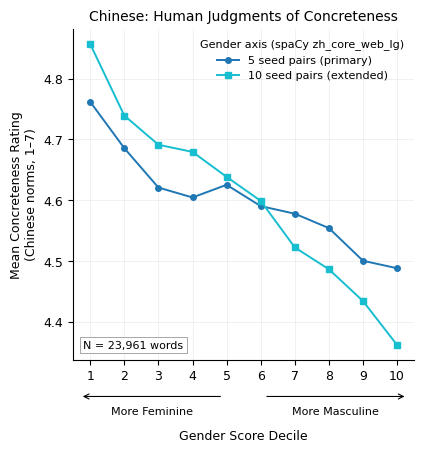

In [7]:
n_words = int(S[(S.seeds == "primary") & (S.specification == "all terms (no controls)")].n.iloc[0])
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
fig, ax = plt.subplots(figsize=(4.4, 4.3))
for pset, label, col, mk in [("primary", "5 seed pairs (primary)", "#1f77b4", "o"), ("extended", "10 seed pairs (extended)", "#17becf", "s")]:
    d = DEC[DEC.seeds == pset].sort_values("decile"); ax.plot(d.decile, d["mean"], marker=mk, ms=4, lw=1.4, color=col, label=label)
ax.set_xticks(range(1, 11)); ax.set_xlim(0.5, 10.5)
ax.set_ylabel(f"Mean Concreteness Rating\n({LANGNAME} norms, {SCALE})")
ax.set_title(f"{LANGNAME}: Human Judgments of Concreteness", fontsize=10); ax.grid(alpha=0.25, lw=0.5)
ax.text(0.03, 0.03, f"N = {n_words:,} words", ha="left", va="bottom", transform=ax.transAxes, fontsize=8, bbox=dict(boxstyle="square,pad=0.3", fc="white", ec="0.6", lw=0.6))
ax.legend(loc="best", fontsize=8, frameon=False, title=f"Gender axis (spaCy {SPACY_MODEL})", title_fontsize=8)
ax.set_xlabel("Gender Score Decile", labelpad=34)
ax.annotate("", xy=(0.02, -0.11), xytext=(0.44, -0.11), xycoords="axes fraction", arrowprops=dict(arrowstyle="->", lw=0.8))
ax.annotate("", xy=(0.98, -0.11), xytext=(0.56, -0.11), xycoords="axes fraction", arrowprops=dict(arrowstyle="->", lw=0.8))
ax.text(0.23, -0.14, "More Feminine", ha="center", va="top", transform=ax.transAxes, fontsize=8)
ax.text(0.77, -0.14, "More Masculine", ha="center", va="top", transform=ax.transAxes, fontsize=8)
for ext in ("png", "pdf"): fig.savefig(OUT_CHAN / f"figS_chinese_replication.{ext}", dpi=300, bbox_inches="tight")
plt.show()

## 5. Check: Song & Li (2021) Mainland Mandarin norms

In [8]:
norms_song = load_norms(NORMS_SONG, word_col="word_chinese", conc_col="concrete_mean", sd_col=None, freq_col="frequency_subtitle", log_freq=True)
print(f"{len(norms_song):,} distinct rated words; concreteness mean {norms_song.conc.mean():.2f} (sd {norms_song.conc.std():.2f}) on a {SCALE} scale")
S2, DEC2, PS2 = run_all(norms_song, "zh_song", OUT_SONG)
display(S2.drop(columns=["language", "model"]).round(4))
display(DEC2.pivot_table(index="decile", columns="seeds", values="mean").round(3))
PS2[["specification", "n_pairs", "r", "ci_lo", "ci_hi", "n", "most_female", "most_male"]].round(3)

3,783 distinct rated words; concreteness mean 4.77 (sd 1.05) on a 1–7 scale
  seeds=primary: 5/5 pairs; 3,782/3,783 words scored; held-out gendered pairs ordered correctly: 1.00 (n=18)
  seeds=extended: 10/10 pairs; 3,782/3,783 words scored; held-out gendered pairs ordered correctly: 0.94 (n=18)
  seeds=pronoun: 5/5 pairs; 3,782/3,783 words scored; held-out gendered pairs ordered correctly: 0.94 (n=18)


,seeds,specification,r,ci_lo,ci_hi,p,rho,n,validation_accuracy,validation_pairs
0,primary,all terms (no controls),-0.1888,-0.2194,-0.1579,0.0,-0.1624,3782,1.0000,18
1,primary,excl. lexically gendered terms + seeds,-0.1689,-0.1999,-0.1375,0.0,-0.1539,3717,1.0000,18
2,primary,excl. 5% most gendered terms,-0.1423,-0.1742,-0.1101,0.0,-0.1323,3592,1.0000,18
3,primary,excl. 10% most gendered terms,-0.1212,-0.1542,-0.0880,0.0,-0.1133,3403,1.0000,18
4,primary,OLS: + log frequency,-0.1835,-0.2167,-0.1502,0.0,NaN,3782,1.0000,18
5,primary,OLS: no controls,-0.1888,-0.2217,-0.1560,0.0,NaN,3782,1.0000,18
6,extended,all terms (no controls),-0.2260,-0.2561,-0.1956,0.0,-0.2027,3782,0.9444,18
7,extended,excl. lexically gendered terms + seeds,-0.2140,-0.2445,-0.1831,0.0,-0.1972,3714,0.9444,18
8,extended,excl. 5% most gendered terms,-0.2090,-0.2401,-0.1775,0.0,-0.1892,3592,0.9444,18
9,extended,excl. 10% most gendered terms,-0.1863,-0.2185,-0.1536,0.0,-0.1710,3403,0.9444,18


seeds,extended,primary,pronoun
decile,,,
1,5.327,5.216,5.360
2,4.896,4.865,5.150
3,4.870,4.831,4.975
4,4.793,4.803,4.821
5,4.848,4.806,4.697
6,4.670,4.694,4.733
7,4.665,4.727,4.607
8,4.610,4.690,4.543
9,4.542,4.532,4.436


,specification,n_pairs,r,ci_lo,ci_hi,n,most_female,most_male
0,primary set (5 pairs),5,-0.189,-0.219,-0.158,3782,"女人, 少女, 女性, 姐姐, 嫂子, 阿姨, 妹妹, 妇女","运气, 离婚, 分析, 预测, 推测, 计算, 属于, 不是"
1,extended set (10 pairs),10,-0.226,-0.256,-0.196,3782,"女人, 女性, 少女, 阿姨, 嫂子, 姐姐, 妹妹, 夫妻","功劳, 运气, 率领, 当年, 祖父, 继承, 子孙, 发誓"
2,primary minus 男人/女人,4,-0.194,-0.224,-0.163,3782,"姐姐, 少女, 嫂子, 女性, 女人, 妹妹, 阿姨, 大嫂","出生, 估计, 运气, 逝世, 祖父, 去世, 效力, 飞行"
3,primary minus 男孩/女孩,4,-0.186,-0.216,-0.155,3782,"女人, 女性, 少女, 姐姐, 嫂子, 阿姨, 妇女, 艺术","运气, 离婚, 属于, 男人, 不是, 购买, 推测, 预测"
4,primary minus 男性/女性,4,-0.215,-0.245,-0.184,3782,"女人, 少女, 姐姐, 嫂子, 阿姨, 女性, 大嫂, 妹妹","运气, 预测, 离婚, 不是, 推测, 成功, 参谋, 分析"
5,primary minus 父亲/母亲,4,-0.122,-0.153,-0.090,3782,"女人, 少女, 女性, 姐姐, 嫂子, 艺术, 阿姨, 妹妹","运气, 男人, 预测, 离婚, 分析, 计算, 推测, 计划"
6,primary minus 哥哥/姐姐,4,-0.188,-0.218,-0.157,3782,"女人, 少女, 女性, 艺术, 妇女, 妹妹, 嫂子, 人体","运气, 离婚, 分析, 预测, 推测, 计算, 男人, 执行"
7,single pair 男人/女人,1,-0.094,-0.126,-0.063,3782,"女人, 女性, 少女, 艺术, 妇女, 人体, 大胆, 女子","男人, 离婚, 做梦, 合法, 预测, 正规, 零钱, 流氓"
8,single pair 男孩/女孩,1,-0.131,-0.162,-0.100,3782,"少女, 妹妹, 女人, 嫂子, 大嫂, 姑娘, 老婆, 姐姐","咳嗽, 发烧, 孩子, 婴儿, 感冒, 武术, 心脏, 背诵"
9,single pair 男性/女性,1,-0.003,-0.034,0.029,3782,"女性, 妇人, 艺术, 妇女, 乡村, 少女, 大胆, 女人","治疗, 保健, 平均, 长度, 打架, 天气, 体重, 死亡"


## 6. Files written

In [9]:
for out in (OUT_CHAN, OUT_SONG):
    print(out.name)
    for f in sorted(out.iterdir()): print("  ", f.name)

results_zh
   deciles_zh.csv
   figS_chinese_replication.pdf
   figS_chinese_replication.png
   pole_sensitivity_zh.csv
   scores_zh.csv
   seeds_zh.json
   stats_zh.csv
results_zh_song
   deciles_zh_song.csv
   pole_sensitivity_zh_song.csv
   scores_zh_song.csv
   seeds_zh_song.json
   stats_zh_song.csv
